# Paper 27: Neural Discrete Representation Learning (VQ-VAE)
**Authors**: Aaron van den Oord, Oriol Vinyals, Koray Kavukcuoglu (DeepMind - NeurIPS 2017)

---

## 1. The Core Breakdown: Continuous VAE Posterior Collapse
In standard continuous VAEs, paired with a powerful autoregressive or deep convolutional decoder, the model frequently falls into **posterior collapse**: $q_\phi(z|x) \to p(z) = \mathcal{N}(0, I)$, making $z$ completely uninformative while the decoder reconstructs by averaging across training modes (producing blurry outputs).

## 2. Vector Quantization & The Discrete Codebook
VQ-VAE resolves this by introducing a discrete embedding dictionary (Codebook) $E = [e_1, \dots, e_K] \in \mathbb{R}^{K \times D}$. Continuous encoder feature vectors $z_e(x)$ are mapped to their nearest codebook vector:
$$k = \arg\min_j \|z_e(x) - e_j\|_2^2, \quad z_q(x) = e_k$$

## 3. The Straight-Through Estimator (STE)
Because the $\arg\min$ operator is non-differentiable (zero gradient almost everywhere), gradients are copied directly from the decoder input $z_q$ to the encoder output $z_e$:
$$z_q^{\text{STE}} = z_e + \operatorname{sg}[z_q - z_e]$$

## 4. The 3-Term Loss Function
$$\mathcal{L} = \underbrace{\mathcal{L}_{\text{recon}}(x, \hat{x})}_{\text{Decoder + Encoder}} + \underbrace{\|\operatorname{sg}[z_e(x)] - z_q\|_2^2}_{\text{Codebook Dictionary Learning}} + \underbrace{\beta \|z_e(x) - \operatorname{sg}[z_q]\|_2^2}_{\text{Commitment Loss}}$$

---
## Setup & Autoreload

In [3]:
%load_ext autoreload
%autoreload 2

import math
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

# Set seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Using device: cpu


---
## Unit Tests Execution
Run the complete verification suite against the reference solution or student template.

In [4]:
import sys
import importlib
from pathlib import Path

# Add repository root to pythonpath
repo_root = Path("../..").resolve()
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

# Local tests and student template
import tests
import model as student_model

# Reference solution (dynamically imported since folder name starts with digits)
solution_model = importlib.import_module("solutions.27_vqvae.model")

print("Testing Reference Solution:")
tests.test_shapes_and_contracts(solution_model)
tests.test_straight_through_gradient_flow(solution_model)
tests.test_perplexity_and_quantization_contracts(solution_model)
tests.test_reconstruction_overfit_gate(solution_model)
print("\nAll tests verified successfully on solution!")

print("\nTesting Student Template (model.py):")
try:
    tests.test_shapes_and_contracts(student_model)
    print("All student tests passed!")
except NotImplementedError as e:
    print(f"Student implementation pending: {e}")

Testing Reference Solution:
Running Test 1: Encoder/Decoder Tensor Shape Contracts... [PASS]
Running Test 2: Straight-Through Estimator & Gradient Audit... [PASS]
Running Test 3: Perplexity & Quantization Metric Contracts... [PASS]
Running Test 4: Discrete Reconstruction Overfit Gate... [PASS] (Loss 1.2720 -> 0.0104)

All tests verified successfully on solution!

Testing Student Template (model.py):
Running Test 1: Encoder/Decoder Tensor Shape Contracts... [PASS]
All student tests passed!


---
## Interactive Experiment: Training VQ-VAE on Geometric Visual Patterns
We create a dataset of 8 geometric patterns (stripes, boxes, gradients, quads) and observe how the codebook adapts and perplexity increases.

Training VQ-VAE on geometric patterns...
Epoch   1 | Total: 1.3592 | Recon: 0.2146 | VQ: 1.1446 | Perplexity: 32.02/64
Epoch  20 | Total: 0.6339 | Recon: 0.0085 | VQ: 0.6254 | Perplexity: 15.26/64
Epoch  40 | Total: 0.1105 | Recon: 0.0031 | VQ: 0.1074 | Perplexity: 12.85/64
Epoch  60 | Total: 0.0387 | Recon: 0.0019 | VQ: 0.0368 | Perplexity: 18.69/64
Epoch  80 | Total: 0.0219 | Recon: 0.0007 | VQ: 0.0212 | Perplexity: 20.00/64
Epoch 100 | Total: 0.0149 | Recon: 0.0003 | VQ: 0.0146 | Perplexity: 20.19/64


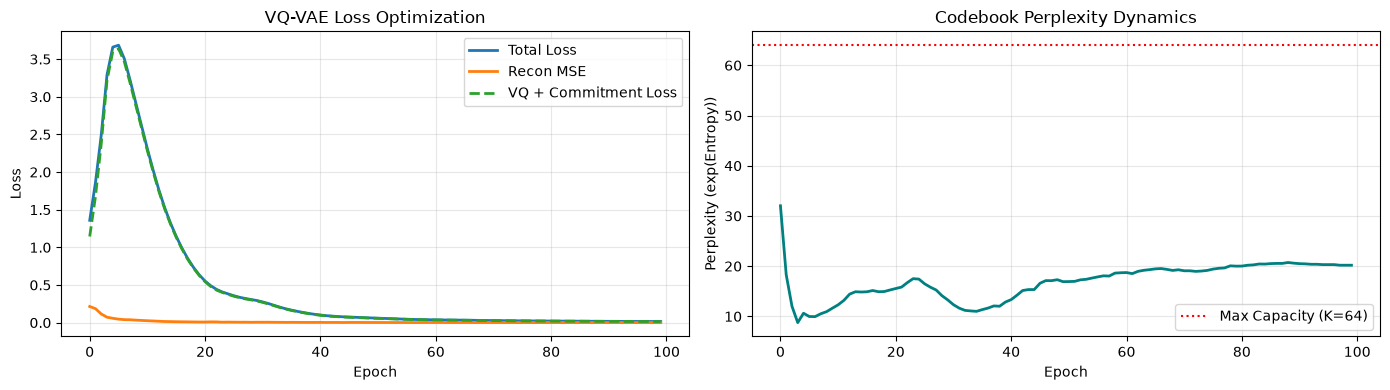

In [5]:
import importlib
solution_model = importlib.import_module("solutions.27_vqvae.model")
VQVAE = solution_model.VQVAE

# Create 8 distinct 28x28 geometric training patterns
x_train = torch.zeros(8, 1, 28, 28, device=device)
x_train[0, 0, :, 12:16] = 1.0           # Vertical stripe
x_train[1, 0, 12:16, :] = 1.0           # Horizontal stripe
x_train[2, 0, 8:20, 8:20] = 1.0         # Center square
x_train[3, 0, :, :] = 0.5               # Uniform gray
x_train[4, 0, :14, :14] = 1.0           # Top-left quad
x_train[5, 0, 14:, 14:] = 1.0           # Bottom-right quad
x_train[6, 0] = torch.linspace(0, 1, 28).unsqueeze(0).repeat(28, 1)  # Gradient H
x_train[7, 0] = torch.linspace(0, 1, 28).unsqueeze(1).repeat(1, 28)  # Gradient V

# Initialize VQ-VAE with 64 codebook embeddings
vqvae = VQVAE(
    in_channels=1,
    hidden_dim=64,
    embedding_dim=32,
    num_embeddings=64,
    commitment_cost=0.25,
).to(device)

optimizer = optim.Adam(vqvae.parameters(), lr=5e-3)
history = {"total": [], "recon": [], "vq": [], "perplexity": []}

print("Training VQ-VAE on geometric patterns...")
for epoch in range(1, 101):
    vqvae.train()
    optimizer.zero_grad()
    x_recon, vq_loss, perplexity, indices = vqvae(x_train)
    recon_loss = F.mse_loss(x_recon, x_train)
    total_loss = recon_loss + vq_loss

    total_loss.backward()
    optimizer.step()

    history["total"].append(total_loss.item())
    history["recon"].append(recon_loss.item())
    history["vq"].append(vq_loss.item())
    history["perplexity"].append(perplexity.item())

    if epoch % 20 == 0 or epoch == 1:
        print(f"Epoch {epoch:3d} | Total: {total_loss.item():.4f} | Recon: {recon_loss.item():.4f} | VQ: {vq_loss.item():.4f} | Perplexity: {perplexity.item():.2f}/64")

# Plot loss trajectories and perplexity
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))
ax1.plot(history["total"], label="Total Loss", lw=2)
ax1.plot(history["recon"], label="Recon MSE", lw=2)
ax1.plot(history["vq"], label="VQ + Commitment Loss", lw=2, linestyle="--")
ax1.set_title("VQ-VAE Loss Optimization")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.grid(True, alpha=0.3)
ax1.legend()

ax2.plot(history["perplexity"], color="teal", lw=2)
ax2.axhline(64, color="red", linestyle=":", label="Max Capacity (K=64)")
ax2.set_title("Codebook Perplexity Dynamics")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Perplexity (exp(Entropy))")
ax2.grid(True, alpha=0.3)
ax2.legend()

plt.tight_layout()
plt.show()

---
## Ground Truth vs. Discrete VQ-VAE Reconstructions

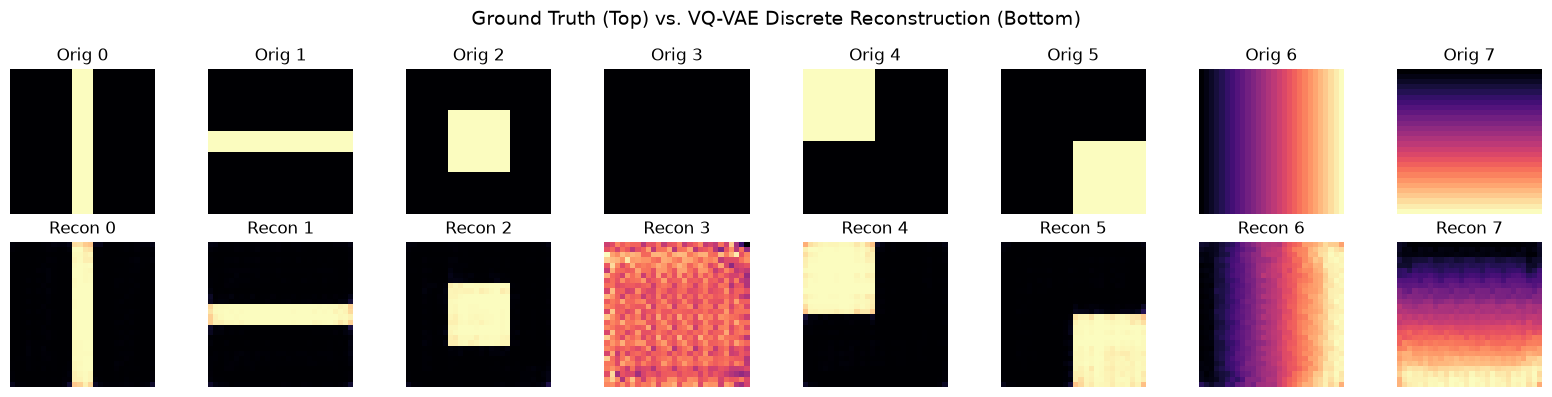

In [6]:
vqvae.eval()
with torch.no_grad():
    x_recon, _, _, indices = vqvae(x_train)

fig, axes = plt.subplots(2, 8, figsize=(16, 4))
for i in range(8):
    axes[0, i].imshow(x_train[i, 0].cpu().numpy(), cmap="magma")
    axes[0, i].axis("off")
    axes[0, i].set_title(f"Orig {i}")

    axes[1, i].imshow(x_recon[i, 0].cpu().numpy(), cmap="magma")
    axes[1, i].axis("off")
    axes[1, i].set_title(f"Recon {i}")

plt.suptitle("Ground Truth (Top) vs. VQ-VAE Discrete Reconstruction (Bottom)", fontsize=14)
plt.tight_layout()
plt.show()

---
## Discrete Codebook Spatial Token Maps ($7 \times 7$ Grid)
Each $28 \times 28$ image is compressed into a $7 \times 7$ grid of discrete integer tokens. Notice how distinct visual textures (backgrounds, edges, corners) are assigned specific codebook index IDs!

<>:7: SyntaxWarning: "\i" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\i"? A raw string is also an option.
<>:7: SyntaxWarning: "\i" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\i"? A raw string is also an option.
C:\Users\hp\AppData\Local\Temp\ipykernel_34384\2755030574.py:7: SyntaxWarning: "\i" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\i"? A raw string is also an option.
  plt.suptitle("Discrete Latent Token Maps $z_q \in \{0, \dots, 63\}^{7 \times 7}$", fontsize=13)


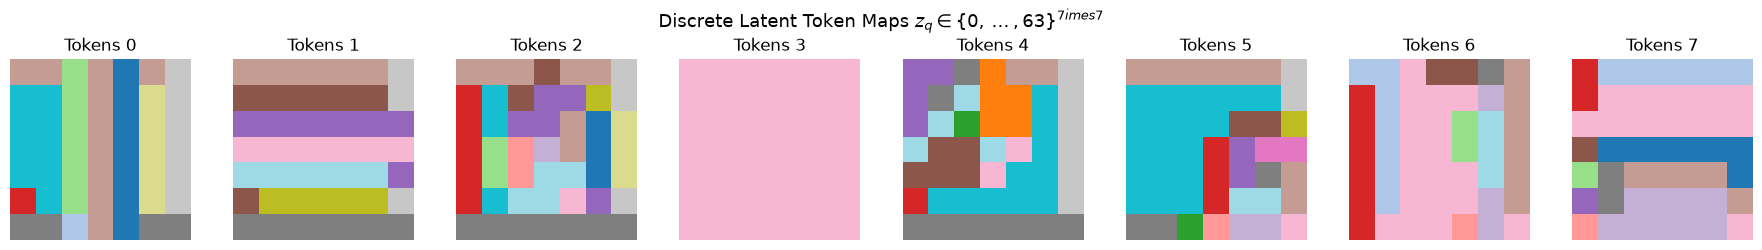

In [7]:
fig, axes = plt.subplots(1, 8, figsize=(18, 2.5))
for i in range(8):
    im = axes[i].imshow(indices[i].cpu().numpy(), cmap="tab20", vmin=0, vmax=63)
    axes[i].axis("off")
    axes[i].set_title(f"Tokens {i}")

plt.suptitle("Discrete Latent Token Maps $z_q \in \{0, \dots, 63\}^{7 \times 7}$", fontsize=13)
plt.tight_layout()
plt.show()

---
## Direct Decoding from Discrete Tokens (`decode_code`)
We can reconstruct directly from pure discrete integer index tensors without touching continuous encoder activations.

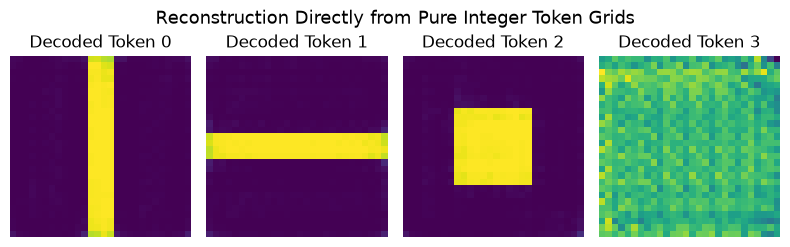

In [8]:
with torch.no_grad():
    # Decode directly from the discrete integer tensor
    direct_recon = vqvae.decode_code(indices)

plt.figure(figsize=(8, 2.5))
for i in range(4):
    plt.subplot(1, 4, i + 1)
    plt.imshow(direct_recon[i, 0].cpu().numpy(), cmap="viridis")
    plt.title(f"Decoded Token {i}")
    plt.axis("off")
plt.suptitle("Reconstruction Directly from Pure Integer Token Grids", fontsize=13)
plt.tight_layout()
plt.show()